In [122]:
# importing important libraries
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.model_selection import train_test_split
import xgboost as xgb
from xgboost import XGBRegressor
from sklearn import metrics
from sklearn.linear_model import Ridge,Lasso

In [44]:
dataset = pd.read_csv('F:\ML Projects\Machine Learning Projects\DataFiles\BostonHousing.csv')

In [45]:
dataset.head()

,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,b,lstat,medv
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2


In [46]:
# shape of the data or size of the data
dataset.shape

(506, 14)

In [47]:
# checking any missing values present in the data

dataset.isna().sum()

# from below we can see that there are no missing values present in the dataset.

crim       0
zn         0
indus      0
chas       0
nox        0
rm         0
age        0
dis        0
rad        0
tax        0
ptratio    0
b          0
lstat      0
medv       0
dtype: int64

In [48]:
dataset.isnull().sum()

crim       0
zn         0
indus      0
chas       0
nox        0
rm         0
age        0
dis        0
rad        0
tax        0
ptratio    0
b          0
lstat      0
medv       0
dtype: int64

In [49]:
# checking any duplicate values present in the data

dataset.duplicated().sum()

# There are no duplicate values present in the dataset.

0

In [50]:
# checking summary of the statistics

dataset.describe()

,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,b,lstat,medv
count,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000
mean,3.613524,11.363636,11.136779,0.069170,0.554695,6.284634,68.574901,3.795043,9.549407,408.237154,18.455534,356.674032,12.653063,22.532806
std,8.601545,23.322453,6.860353,0.253994,0.115878,0.702617,28.148861,2.105710,8.707259,168.537116,2.164946,91.294864,7.141062,9.197104
min,0.006320,0.000000,0.460000,0.000000,0.385000,3.561000,2.900000,1.129600,1.000000,187.000000,12.600000,0.320000,1.730000,5.000000
25%,0.082045,0.000000,5.190000,0.000000,0.449000,5.885500,45.025000,2.100175,4.000000,279.000000,17.400000,375.377500,6.950000,17.025000
50%,0.256510,0.000000,9.690000,0.000000,0.538000,6.208500,77.500000,3.207450,5.000000,330.000000,19.050000,391.440000,11.360000,21.200000
75%,3.677083,12.500000,18.100000,0.000000,0.624000,6.623500,94.075000,5.188425,24.000000,666.000000,20.200000,396.225000,16.955000,25.000000
max,88.976200,100.000000,27.740000,1.000000,0.871000,8.780000,100.000000,12.126500,24.000000,711.000000,22.000000,396.900000,37.970000,50.000000


<Axes: >

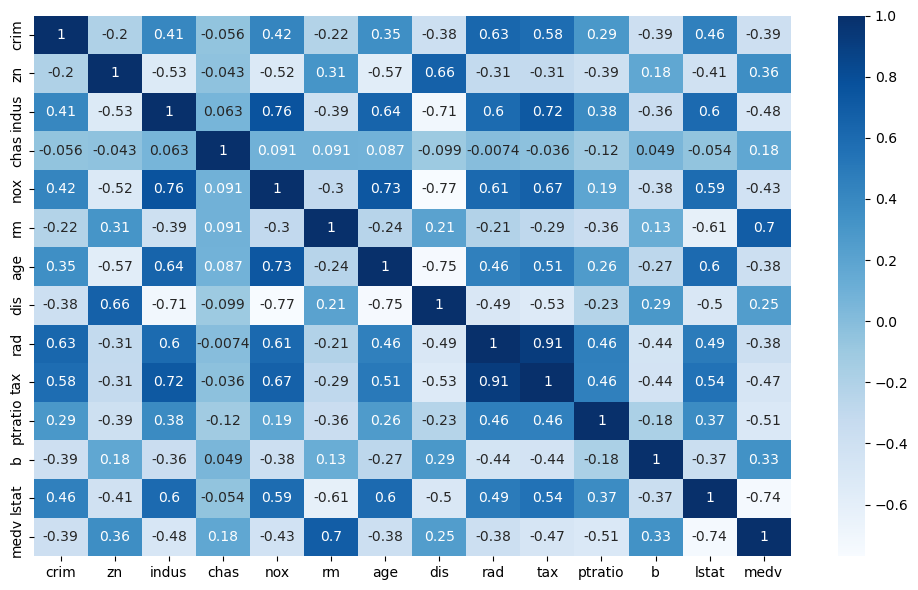

In [51]:
# understanding correlation between the features.

plt.figure(figsize=(10,6),layout='tight')
sns.heatmap(dataset.corr(),annot=True,cmap='Blues')

In [52]:
# dividing the data set in to independent and dependent varibles

X = dataset.drop('medv',axis=1)
y = dataset['medv']

In [53]:
# splitting the data set into train test split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=22)

In [54]:
# we dont need to scale the data for xg boost we can apply the data directly.

xgb_regressor = XGBRegressor()

In [55]:
# fitting the data to the model 

xgb_regressor.fit(X_train,y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             gamma=None, grow_policy=None, importance_type=None,
             interaction_constraints=None, learning_rate=None, max_bin=None,
             max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=None, max_leaves=None,
             min_child_weight=None, missing=nan, monotone_constraints=None,
             multi_strategy=None, n_estimators=None, n_jobs=None,
             num_parallel_tree=None, random_state=None, ...)

In [56]:
# we will check how the model is going to train with the training data

X_pred = xgb_regressor.predict(X_train)

# we will check the accuracy of the model with x_train data

score = metrics.r2_score(X_pred,y_train)
print(score)

MAE = metrics.mean_absolute_error(X_pred,y_train)
print(MAE)

0.9999935852578057
0.01592125467734769


In [57]:
y_pred = xgb_regressor.predict(X_test)

In [58]:
# prediction on test data

score1 = metrics.r2_score(y_pred,y_test)

print(score1)

MAE1 = metrics.mean_absolute_error(y_pred,y_test)

print(MAE1)

0.8089061186162916
2.6692174350514137


In [59]:
df = pd.read_csv('F:\ML Projects\Machine Learning Projects\DataFiles\BostonHousing.csv')

In [60]:
df.head()

,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,b,lstat,medv
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2


In [61]:
# checking any missing values are present in the dataset

df.isnull().sum()

crim       0
zn         0
indus      0
chas       0
nox        0
rm         0
age        0
dis        0
rad        0
tax        0
ptratio    0
b          0
lstat      0
medv       0
dtype: int64

In [62]:
df.isna().sum()

crim       0
zn         0
indus      0
chas       0
nox        0
rm         0
age        0
dis        0
rad        0
tax        0
ptratio    0
b          0
lstat      0
medv       0
dtype: int64

<Axes: >

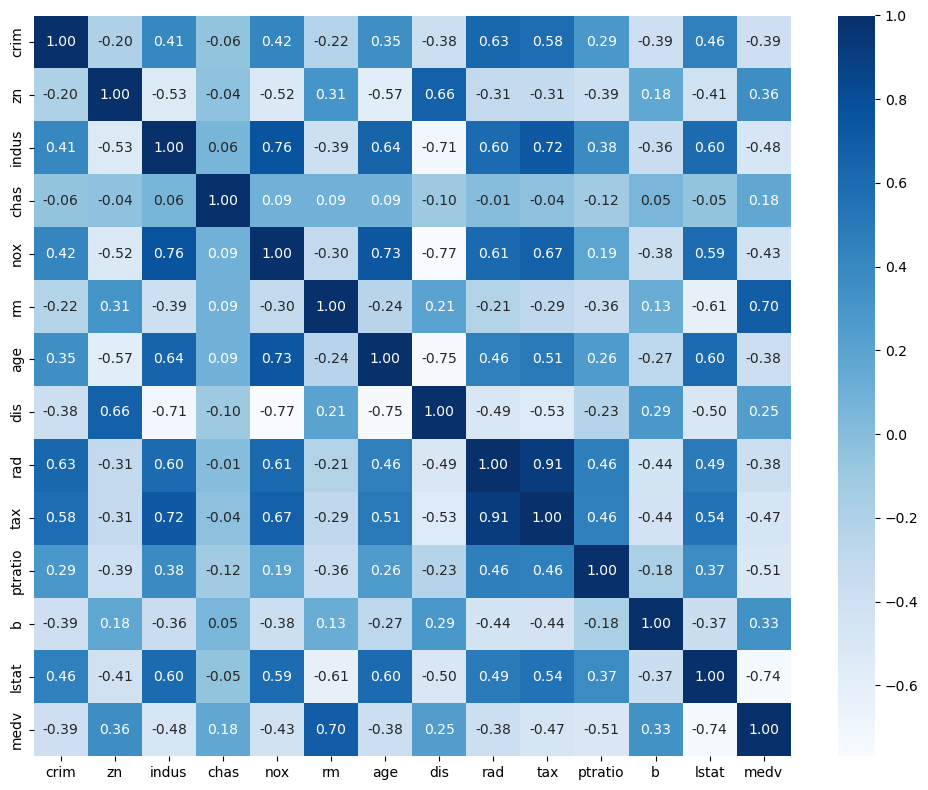

In [72]:
plt.figure(figsize=(10,8),layout='tight')
sns.heatmap(df.corr(),annot=True,cmap='Blues',fmt='.2f')

In [73]:
# dividing the data set in to independent and dependent varibles

X = dataset.drop('medv',axis=1)
y = dataset['medv']

In [90]:
# splitting the data set into train test split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=22)

In [91]:
from sklearn.preprocessing import StandardScaler

In [92]:
scalar = StandardScaler()

X_train = scalar.fit_transform(X_train)
X_test = scalar.transform(X_test)

In [93]:
# Importing all the regression models.

from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor

In [131]:
models = {'LR': LinearRegression(),
          'SVR' : SVR(),
          'DT': DecisionTreeRegressor(),
          'KNN': KNeighborsRegressor(),
          'RFR':RandomForestRegressor(),
          'Lasso': Lasso(),
          'ridge':Ridge()
          }

In [132]:
model_list = []
acc_score2 = []

for i in range(len(models)):
    model_name = list(models.keys())[i]
    model = list(models.values())[i]

    # Fit
    model.fit(X_train, y_train)

    # Predict
    y_pred = model.predict(X_test)

    # Evaluation
    MAE, MSE, R2 = evaluation(y_test.values, y_pred)

    print(model_name)

    model_list.append(model_name)

    print('Model Testing Performance')
    print("MAE :", MAE)
    print("MSE :", MSE)
    print("R2  :", R2)

    acc_score2.append(R2)    

    print('=' * 35, '\n')


LR
Model Testing Performance
MAE : 3.4251818718533666
MSE : 20.770684784270067
R2  : 0.7657465943591119

SVR
Model Testing Performance
MAE : 3.2304243104562134
MSE : 28.15748282833051
R2  : 0.6824377089480226

DT
Model Testing Performance
MAE : 3.0656862745098046
MSE : 17.184607843137258
R2  : 0.8061906502520981

KNN
Model Testing Performance
MAE : 2.7549019607843133
MSE : 19.294047058823534
R2  : 0.7824002299843381

RFR
Model Testing Performance
MAE : 2.4142745098039198
MSE : 15.179419411764698
R2  : 0.8288053220301062

Lasso
Model Testing Performance
MAE : 4.220737383349322
MSE : 29.673205493975523
R2  : 0.6653432703138509

ridge
Model Testing Performance
MAE : 3.4296516024663704
MSE : 20.796399382114036
R2  : 0.7654565831157562



In [119]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

def evaluation(y_true, y_pred):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    MAE = mean_absolute_error(y_true, y_pred)
    MSE = mean_squared_error(y_true, y_pred)
    R2  = r2_score(y_true, y_pred)

    return MAE, MSE, R2


In [120]:
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score